# AI-Based Crop Disease Detection Using Leaf Images


---



**Project Overview**

This project explores the use of deep learning to detect plant diseases from leaf images.

Using the PlantVillage dataset, two convolutional neural network architectures, MobileNetV2 and ResNet50, are developed and evaluated for multi-class plant disease classification.

The objective is to compare their classification performance and investigate how transfer learning can be applied to automated plant disease detection.

**Models**

- MobileNetV2
- ResNet50

**Dataset**

PlantVillage dataset containing 54,304 images across 38 plant disease and healthy leaf categories.


---



In [5]:
## Install dependencies
!pip install -q datasets scikit-learn matplotlib pandas

In [6]:
## Import Libraries
from datasets import load_dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

**Dataset Loading**

Loading PlantVillage images...


README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]


Dataset loaded!
Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})

Available columns:
['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']

First example:
Class: Apple___Apple_scab
Split: test
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (256, 256)


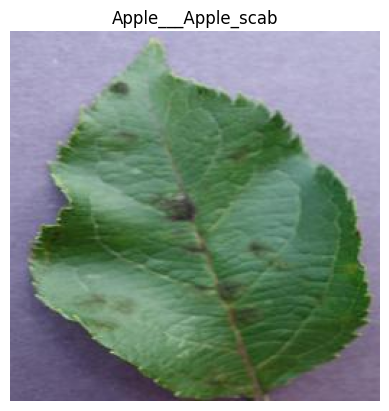

In [7]:
print("Loading PlantVillage images...")

plant_dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print("\nDataset loaded!")
print(plant_dataset)

print("\nAvailable columns:")
print(plant_dataset.column_names)

print("\nFirst example:")
example = plant_dataset[0]

print("Class:", example["class_label"])
print("Split:", example["split"])
print("Image type:", type(example["image"]))
print("Image size:", example["image"].size)

# Display the actual leaf photograph
import matplotlib.pyplot as plt

plt.imshow(example["image"])
plt.title(example["class_label"])
plt.axis("off")
plt.show()


######**SECTION 3: Check available classes**

In [8]:

# Section 3: Check the available classes

print("Number of classes:", len(set(plant_dataset["class_label"])))

print("\nAvailable classes:")

classes = sorted(set(plant_dataset["class_label"]))

for class_name in classes:
    print(class_name)


Number of classes: 38

Available classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosa

In [9]:

# Section 4: Count images in all 38 classes

from collections import Counter

class_counts = Counter(plant_dataset["class_label"])

print("Number of classes:", len(class_counts))
print("Total number of images:", len(plant_dataset))

print("\nNumber of images per class:\n")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")


Number of classes: 38
Total number of images: 54304

Number of images per class:

Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1477
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early

In [10]:

# Section 6: Check the dataset splits

from collections import Counter

split_counts = Counter(plant_dataset["split"])

print("Images in each split:\n")

for split_name, count in sorted(split_counts.items()):
    print(f"{split_name}: {count}")

print("\nExample images from each split:")

for split_name in sorted(split_counts.keys()):
    example = next(
        item for item in plant_dataset
        if item["split"] == split_name
    )
    print(f"{split_name}: {example['class_label']}")


Images in each split:

test: 10948
train: 43356

Example images from each split:
test: Apple___Apple_scab
train: Apple___Apple_scab


In [11]:

# Section 7: Check class distribution in each split

from collections import defaultdict, Counter

split_class_counts = defaultdict(Counter)

for split_name, class_name in zip(
    plant_dataset["split"],
    plant_dataset["class_label"]
):
    split_class_counts[split_name][class_name] += 1

for split_name in sorted(split_class_counts):
    counts = split_class_counts[split_name]

    print(f"\n{split_name.upper()} SPLIT")
    print("Number of classes:", len(counts))
    print("Total images:", sum(counts.values()))

    missing_classes = set(classes) - set(counts)

    if missing_classes:
        print("Missing classes:", sorted(missing_classes))
    else:
        print("All 38 classes are present.")



TEST SPLIT
Number of classes: 38
Total images: 10948
All 38 classes are present.

TRAIN SPLIT
Number of classes: 38
Total images: 43356
All 38 classes are present.


**Training, validation, and test sets**


In [12]:


from sklearn.model_selection import train_test_split

# Keep the existing training and test groups separate
train_records = plant_dataset.filter(
    lambda example: example["split"] == "train"
)

test_records = plant_dataset.filter(
    lambda example: example["split"] == "test"
)

# Create a validation set from the training records
train_indices, val_indices = train_test_split(
    range(len(train_records)),
    test_size=0.15,
    random_state=42,
    stratify=train_records["class_label"]
)

# Select the records for each group
train_data = train_records.select(train_indices)
val_data = train_records.select(val_indices)

print("Data preparation complete!")
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_records))
print("Total images:", len(train_data) + len(val_data) + len(test_records))


Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Data preparation complete!
Training images: 36852
Validation images: 6504
Testing images: 10948
Total images: 54304


Image class: Pepper,_bell___Bacterial_spot
Image shape: (224, 224, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


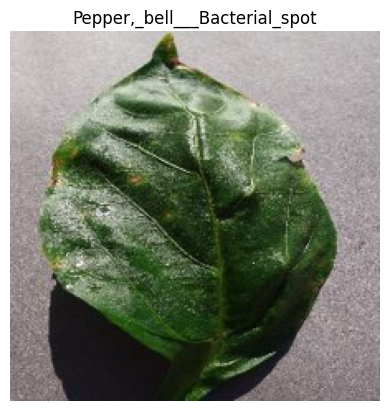

In [15]:

# Test image preprocessing

import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224

# Load one image from the training data
sample = train_data[0]

# Convert the image to RGB and resize it
sample_image = sample["image"].convert("RGB").resize(
    (IMG_SIZE, IMG_SIZE)
)

# Convert the image to a NumPy array
sample_array = np.array(sample_image)

print("Image class:", sample["class_label"])
print("Image shape:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())

# Display the processed image
plt.imshow(sample_array)
plt.title(sample["class_label"])
plt.axis("off")
plt.show()


In [16]:

# Create a batch-based image pipeline

import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Create a consistent mapping from class names to integer labels
class_names = sorted(set(plant_dataset["class_label"]))
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMG_SIZE, "x", IMG_SIZE)

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label



def make_dataset(dataset, training=False):
    def generator():
        for example in dataset:
            image = np.array(
                example["image"].convert("RGB"),
                dtype=np.uint8
            )
            label = class_to_index[example["class_label"]]
            yield image, np.int32(label)

    output_signature = (
        tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )

    data = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if training:
        data = data.shuffle(1000, seed=42)

    data = data.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )
    data = data.batch(BATCH_SIZE)

    # Tell TensorFlow how many batches to expect
    import math
    expected_batches = math.ceil(len(dataset) / BATCH_SIZE)
    data = data.apply(
        tf.data.experimental.assert_cardinality(expected_batches)
    )

    return data.prefetch(AUTOTUNE)

print("Pipeline functions created successfully.")


Number of classes: 38
Batch size: 32
Image size: 224 x 224
Pipeline functions created successfully.


In [17]:


# Create the data pipelines

train_ds = make_dataset(train_data, training=True)
val_ds = make_dataset(val_data)
test_ds = make_dataset(test_records)

# Calculate the number of batches (rounding up)
import math

print("All three data pipelines have been created!")
print("Training batches:", math.ceil(len(train_data) / BATCH_SIZE))
print("Validation batches:", math.ceil(len(val_data) / BATCH_SIZE))
print("Test batches:", math.ceil(len(test_records) / BATCH_SIZE))


All three data pipelines have been created!
Training batches: 1152
Validation batches: 204
Test batches: 343


In [18]:

# Check one batch of training images

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [30 35 25 11 25 35  3 11 30  3]


In [19]:

# Build MobileNetV2

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:

# Train MobileNetV2

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping]
)


Epoch 1/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 129s 98ms/step - accuracy: 0.8705 - loss: 0.4820 - val_accuracy: 0.9390 - val_loss: 0.2082
Epoch 2/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 126s 93ms/step - accuracy: 0.9435 - loss: 0.1888 - val_accuracy: 0.9505 - val_loss: 0.1582
Epoch 3/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 110s 94ms/step - accuracy: 0.9542 - loss: 0.1471 - val_accuracy: 0.9537 - val_loss: 0.1405
Epoch 4/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 112s 96ms/step - accuracy: 0.9596 - loss: 0.1248 - val_accuracy: 0.9513 - val_loss: 0.1423
Epoch 5/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 116s 98ms/step - accuracy: 0.9631 - loss: 0.1139 - val_accuracy: 0.9569 - val_loss: 0.1344


In [21]:

# Section 17: Build ResNet50

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

base_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_resnet.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_resnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [22]:

# Train ResNet50

resnet_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[resnet_early_stopping]
)


Epoch 1/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 159s 126ms/step - accuracy: 0.9104 - loss: 0.3428 - val_accuracy: 0.9703 - val_loss: 0.1103
Epoch 2/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 146s 125ms/step - accuracy: 0.9709 - loss: 0.0988 - val_accuracy: 0.9774 - val_loss: 0.0781
Epoch 3/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 144s 123ms/step - accuracy: 0.9779 - loss: 0.0712 - val_accuracy: 0.9789 - val_loss: 0.0667
Epoch 4/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 151s 130ms/step - accuracy: 0.9822 - loss: 0.0559 - val_accuracy: 0.9822 - val_loss: 0.0581
Epoch 5/5
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 146s 125ms/step - accuracy: 0.9843 - loss: 0.0482 - val_accuracy: 0.9851 - val_loss: 0.0492


**Evaluation**

In [23]:

# Evaluate both models on the test set

mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    test_ds, verbose=1
)

resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    test_ds, verbose=1
)

print("\nTest Results")
print(f"MobileNetV2 accuracy: {mobilenet_test_accuracy:.4f}")
print(f"MobileNetV2 loss: {mobilenet_test_loss:.4f}")
print(f"ResNet50 accuracy: {resnet_test_accuracy:.4f}")
print(f"ResNet50 loss: {resnet_test_loss:.4f}")


343/343 ━━━━━━━━━━━━━━━━━━━━ 25s 74ms/step - accuracy: 0.9475 - loss: 0.1569
343/343 ━━━━━━━━━━━━━━━━━━━━ 38s 111ms/step - accuracy: 0.9797 - loss: 0.0673

Test Results
MobileNetV2 accuracy: 0.9475
MobileNetV2 loss: 0.1569
ResNet50 accuracy: 0.9797
ResNet50 loss: 0.0673


In [24]:

# Compare precision, recall, and F1-score

from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

mobilenet_predictions = np.argmax(
    mobilenet_model.predict(test_ds, verbose=1), axis=1
)

resnet_predictions = np.argmax(
    resnet_model.predict(test_ds, verbose=1), axis=1
)

print("MobileNetV2 classification report:")
print(classification_report(
    y_true,
    mobilenet_predictions,
    target_names=class_names,
    digits=3,
    zero_division=0
))

print("\nResNet50 classification report:")
print(classification_report(
    y_true,
    resnet_predictions,
    target_names=class_names,
    digits=3,
    zero_division=0
))


343/343 ━━━━━━━━━━━━━━━━━━━━ 35s 92ms/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step
MobileNetV2 classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.973     0.878     0.923       123
                                 Apple___Black_rot      0.992     0.960     0.975       124
                          Apple___Cedar_apple_rust      0.981     0.964     0.972        55
                                   Apple___healthy      0.978     0.981     0.980       324
                               Blueberry___healthy      0.982     1.000     0.991       278
          Cherry_(including_sour)___Powdery_mildew      0.988     0.996     0.992       252
                 Cherry_(including_sour)___healthy      0.989     1.000     0.994       179
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.822     0.806     0.814       103
                       Corn_(maize)___Common_rust

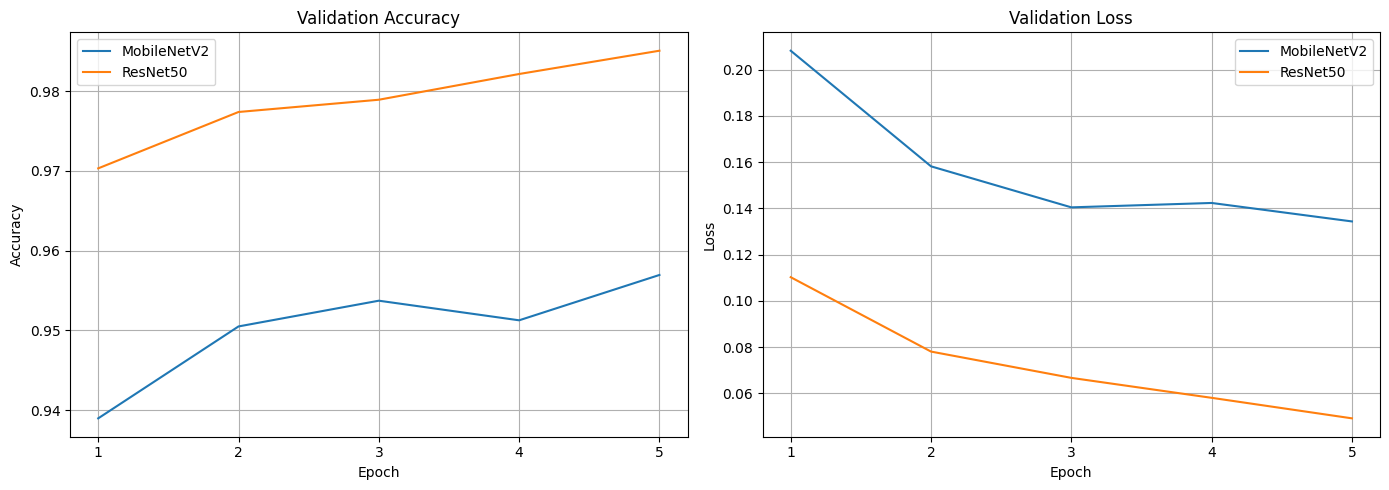

In [31]:

# Plot training and validation curves

import matplotlib.pyplot as plt

mobilenet_epochs = range(
    1, len(mobilenet_history.history["val_accuracy"]) + 1
)

resnet_epochs = range(
    1, len(resnet_history.history["val_accuracy"]) + 1
)

max_epochs = max(len(mobilenet_epochs), len(resnet_epochs))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation accuracy
axes[0].plot(
    mobilenet_epochs,
    mobilenet_history.history["val_accuracy"],
    label="MobileNetV2"
)
axes[0].plot(
    resnet_epochs,
    resnet_history.history["val_accuracy"],
    label="ResNet50"
)
axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(range(1, max_epochs + 1))
axes[0].legend()
axes[0].grid(True)

# Validation loss
axes[1].plot(
    mobilenet_epochs,
    mobilenet_history.history["val_loss"],
    label="MobileNetV2"
)
axes[1].plot(
    resnet_epochs,
    resnet_history.history["val_loss"],
    label="ResNet50"
)
axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(1, max_epochs + 1))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:

# Save the trained models

mobilenet_model.save("mobilenetv2_plant_disease.keras")
resnet_model.save("resnet50_plant_disease.keras")

print("Both models saved successfully!")


Both models saved successfully!


In [27]:

# Summarise model performance

results = pd.DataFrame({
    "Model": ["MobileNetV2", "ResNet50"],
    "Test Accuracy": [
        mobilenet_test_accuracy,
        resnet_test_accuracy
    ],
    "Test Loss": [
        mobilenet_test_loss,
        resnet_test_loss
    ],
    "Macro F1-score": [
        f1_score(y_true, mobilenet_predictions, average="macro"),
        f1_score(y_true, resnet_predictions, average="macro")
    ],
    "Weighted F1-score": [
        f1_score(y_true, mobilenet_predictions, average="weighted"),
        f1_score(y_true, resnet_predictions, average="weighted")
    ]
})

results[["Test Accuracy", "Macro F1-score", "Weighted F1-score"]] = (
    results[["Test Accuracy", "Macro F1-score", "Weighted F1-score"]] * 100
).round(2)

results["Test Loss"] = results["Test Loss"].round(4)

print(results.to_string(index=False))


      Model  Test Accuracy  Test Loss  Macro F1-score  Weighted F1-score
MobileNetV2          94.75     0.1569           93.52              94.69
   ResNet50          97.97     0.0673           97.02              97.97


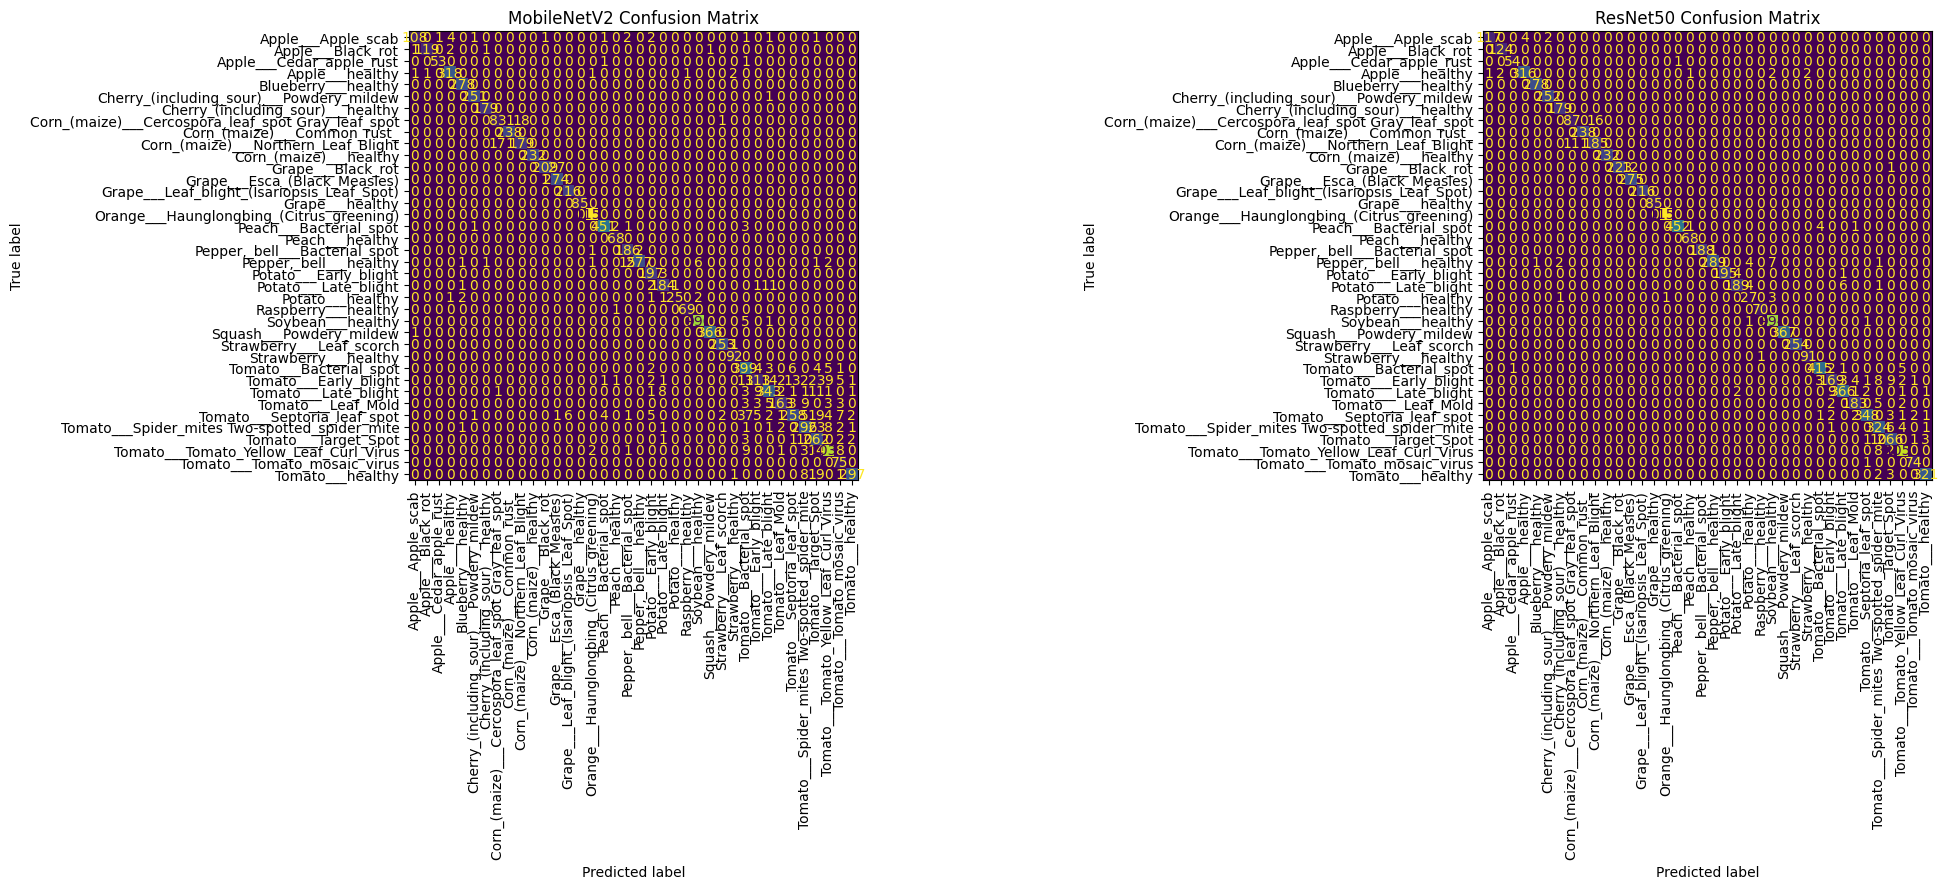

In [30]:

# Create confusion matrices

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

mobilenet_cm = confusion_matrix(y_true, mobilenet_predictions)
resnet_cm = confusion_matrix(y_true, resnet_predictions)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=class_names
).plot(ax=axes[0], xticks_rotation=90, colorbar=False, values_format="d")

axes[0].set_title("MobileNetV2 Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=class_names
).plot(ax=axes[1], xticks_rotation=90, colorbar=False, values_format="d")

axes[1].set_title("ResNet50 Confusion Matrix")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


**Conclusion**

This project investigated the use of transfer learning for plant disease classification using leaf images from the PlantVillage dataset.

Two convolutional neural network architectures, MobileNetV2 and ResNet50, were trained and evaluated across 38 plant disease and healthy-leaf categories.

The results showed that ResNet50 achieved higher classification performance than MobileNetV2 on the test dataset. Both models demonstrated strong performance in identifying plant diseases from leaf images.

Overall, the project demonstrates the potential of deep learning and transfer learning for automated plant disease detection. However, further evaluation using images captured under real-world agricultural conditions would be necessary to assess how well the models generalise beyond the PlantVillage dataset.